# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

In [156]:
!pip install torch torchvision optuna catalyst opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 339.5 kB/s  0:01:38m0:00:0100:05

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [157]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import optuna
import cv2
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, accuracy_score
from torch import nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, ConcatDataset
from torchvision import transforms

In [152]:
def plot_confusion_matrix(cm):  
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title('Confusion Matrix')
    plt.xlabel('Przewidziana klasa')
    plt.ylabel('Prawdziwa klasa')
    plt.show()

In [89]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

In [125]:
class BloodMNISTDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels.squeeze().astype('int64')
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self,id):
        img = self.images[id]
        label = self.labels[id]

        if self.transform:
            img = self.transform(img)

        return img, torch.tensor(label, dtype=torch.long)

Kształt X_train: (11959, 28, 28, 3)
Kształt y_train: (11959, 1)


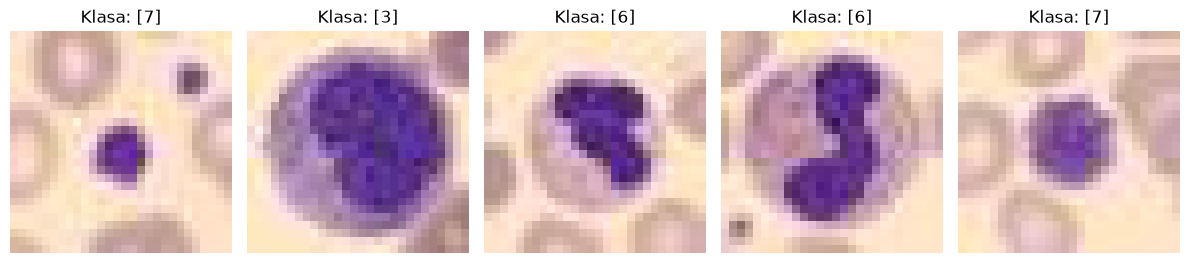

In [126]:
X_train = data['train_images']
y_train = data['train_labels']
X_val = data['val_images']
y_val = data['val_labels']
X_test = data['test_images']
y_test = data['test_labels']

print('Kształt X_train:', X_train.shape)
print('Kształt y_train:', y_train.shape)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
  img = X_train[i]
  ax.imshow(img)
  ax.axis('off')

  label = y_train[i]
  ax.set_title(f'Klasa: {label}')

plt.tight_layout()
plt.show()

In [127]:
classes, counts = np.unique(y_train, return_counts=True)
for cls, count in zip(classes, counts):
  print(f'Klasa {cls}: {count} próbek')

print("Typ danych: ",X_train.dtype)
print("Zakres pikseli: ",X_train.min(),"-",X_train.max())
print("Wartości NaN: ", np.isnan(X_train).sum())
print("Kanały:", X_train.shape[-1])

print(
    'Czy każdy obraz ma wymiar 28x28x3?',
    all(img.shape == (28, 28, 3) for img in X_train),
)
weights = 1.0/counts
w_mean = np.mean(weights)
weights = weights/w_mean


Klasa 0: 852 próbek
Klasa 1: 2181 próbek
Klasa 2: 1085 próbek
Klasa 3: 2026 próbek
Klasa 4: 849 próbek
Klasa 5: 993 próbek
Klasa 6: 2330 próbek
Klasa 7: 1643 próbek
Typ danych:  uint8
Zakres pikseli:  0 - 255
Wartości NaN:  0
Kanały: 3
Czy każdy obraz ma wymiar 28x28x3? True


Mamy kolorowe obrazy o rozmiarze 28x28 pikseli, liczba próbek nie jest równomierna więc wyliczamay wagi, których uzyjemy potem przy wyliczaniu funkcji kosztu, by model nie faworyzował liczniejszych klas. 

In [129]:
weights

array([1.49750998, 0.58499702, 1.17592489, 0.62975247, 1.50280153,
       1.28487261, 0.54758734, 0.77655417])

In [130]:
m = X_train.mean(axis=(0,1,2))/255.0
s = X_train.std(axis=(0,1,2))/255.0

train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ToTensor(),
    transforms.Normalize(mean=[m[0],m[1],m[2]], std=[s[0],s[1],s[2]])
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[m[0],m[1],m[2]], std=[s[0],s[1],s[2]])
])


Dane normalizujemy, i stosujemy augumentację w zbiorze treningowym, by model miał więcej danych do treningu. 

In [132]:
train_dataset = BloodMNISTDataset(
    images=X_train,
    labels=y_train,
    transform=train_transform
)
valid_dataset = BloodMNISTDataset(
    images=X_val, 
    labels=y_val, 
    transform=val_transform
)
test_dataset = BloodMNISTDataset(
    images=X_test, 
    labels=y_test, 
    transform=val_transform
)

batch_size = 64

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,          
)

val_loader = DataLoader(
    dataset= valid_dataset,
    batch_size=batch_size,
    shuffle=False,
)

test_loader = DataLoader(
    dataset= test_dataset,
    batch_size=batch_size,
    shuffle=False,
)

## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

In [196]:
def define_model(trial: optuna.trial.Trial) -> nn.Sequential:
    num_blocks = trial.suggest_int("num_blocks", 2, 3) 
    dropout = trial.suggest_float("dropout", 0.2, 0.5)
    
    layers = []
    input_dim = 3
    
    for i in range(num_blocks):
        output_dim = trial.suggest_int(f"n_units_conv_{i}", 32, 128, log=True)
        
        layers.append(nn.Conv2d(input_dim, output_dim, kernel_size=3, padding=1))
        layers.append(nn.BatchNorm2d(output_dim))
        layers.append(nn.ReLU())
        layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
        
        input_dim = output_dim

    conv_layers = nn.Sequential(*layers)
    layers.append(nn.Flatten())
    
    conv_submodel = nn.Sequential(*layers)
    with torch.no_grad():
        dummy_input = torch.zeros(1, 3, 28, 28)
        input_dim_linear = conv_submodel(dummy_input).shape[1]
        
    hidden_dim = trial.suggest_int("n_units_lin", 32, 128, log=True)
    layers.append(nn.Linear(input_dim_linear, hidden_dim))
    layers.append(nn.BatchNorm1d(hidden_dim))
    layers.append(nn.ReLU())
    layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(hidden_dim, 8)) 
    
    return nn.Sequential(*layers), conv_layers

In [220]:
def objective(trial):
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    model, conv_model = define_model(trial)
    model = model.to(device)
    conv_model = conv_model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    class_weights = torch.tensor(weights, dtype=torch.float32).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    model.train()
    for epoch in range(15):
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            output = model(batch_x) 
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            output = model(batch_x)
            _, predicted = torch.max(output.data, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()
            
    accuracy = correct / total
    

    return accuracy


if __name__ == "__main__":
    study = optuna.create_study(
        direction="maximize", 
    )
    
    study.optimize(objective, n_trials=20)
    
    print("Best accuracy):", study.best_value)
    print("Best hiperparameters:")
    for key, value in study.best_params.items():
        print(f"  {key}: {value}")

[I 2026-10-30 17:14:30,904] A new study created in memory with name: no-name-ed506484-fca3-40c9-9b7d-7665dbe56299
/var/folders/hx/vyl7fthj7zs6kl3wzjy1x_480000gn/T/ipykernel_94726/2919993388.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  class_weights = torch.tensor(weights, dtype=torch.float32).to(device)
[I 2026-10-30 17:15:00,742] Trial 0 finished with value: 0.9059579439252337 and parameters: {'lr': 0.0024655974504760015, 'num_blocks': 3, 'dropout': 0.3478688217297637, 'n_units_conv_0': 78, 'n_units_conv_1': 119, 'n_units_conv_2': 33, 'n_units_lin': 120}. Best is trial 0 with value: 0.9059579439252337.
[I 2026-10-30 17:15:15,466] Trial 1 finished with value: 0.9433411214953271 and parameters: {'lr': 0.00023442869121212498, 'num_blocks': 2, 'dropout': 0.3236388725392771, 'n_units_conv_0': 36, 'n_units_conv_1': 70, 'n_units_lin': 

Best accuracy): 0.9509345794392523
Best hiperparameters:
  lr: 0.0014450293643179927
  num_blocks: 2
  dropout: 0.40069356128718336
  n_units_conv_0: 43
  n_units_conv_1: 92
  n_units_lin: 126


In [136]:
combined_dataset = ConcatDataset([train_dataset,valid_dataset])

final_loader = DataLoader(
    combined_dataset, 
    batch_size=64, 
    shuffle=True
)

In [227]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
lr = study.best_params["lr"]
model,conv_model = define_model(optuna.trial.FixedTrial(study.best_params))
model = model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
weights = torch.tensor(weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)

model.train()
for epoch in range(30):
    running_loss = 0.0
    for batch_x, batch_y in final_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        output = model(batch_x) 
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    avg_loss = running_loss / len(final_loader)
    print(f"Epoka {epoch+1}/30 | Średnia strata (Loss): {avg_loss:.4f}")

/var/folders/hx/vyl7fthj7zs6kl3wzjy1x_480000gn/T/ipykernel_94726/2790530008.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  weights = torch.tensor(weights, dtype=torch.float32).to(device)


Epoka 1/30 | Średnia strata (Loss): 0.6814
Epoka 2/30 | Średnia strata (Loss): 0.3996
Epoka 3/30 | Średnia strata (Loss): 0.3365
Epoka 4/30 | Średnia strata (Loss): 0.2978
Epoka 5/30 | Średnia strata (Loss): 0.2804
Epoka 6/30 | Średnia strata (Loss): 0.2522
Epoka 7/30 | Średnia strata (Loss): 0.2530
Epoka 8/30 | Średnia strata (Loss): 0.2261
Epoka 9/30 | Średnia strata (Loss): 0.2241
Epoka 10/30 | Średnia strata (Loss): 0.2062
Epoka 11/30 | Średnia strata (Loss): 0.2037
Epoka 12/30 | Średnia strata (Loss): 0.1930
Epoka 13/30 | Średnia strata (Loss): 0.1891
Epoka 14/30 | Średnia strata (Loss): 0.1893
Epoka 15/30 | Średnia strata (Loss): 0.1846
Epoka 16/30 | Średnia strata (Loss): 0.1808
Epoka 17/30 | Średnia strata (Loss): 0.1717
Epoka 18/30 | Średnia strata (Loss): 0.1633
Epoka 19/30 | Średnia strata (Loss): 0.1687
Epoka 20/30 | Średnia strata (Loss): 0.1610
Epoka 21/30 | Średnia strata (Loss): 0.1558
Epoka 22/30 | Średnia strata (Loss): 0.1588
Epoka 23/30 | Średnia strata (Loss): 0.15

test_auroc: 0.9973
accuracy: 0.9503
precision: 0.9453
recall: 0.9491
f1: 0.9462


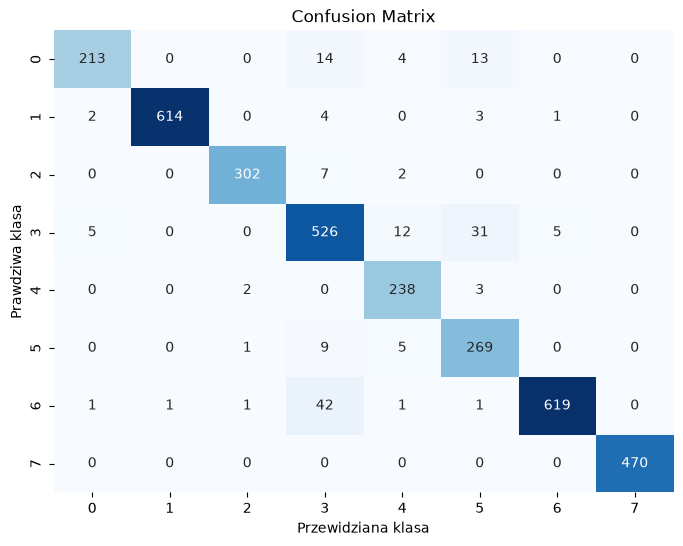

In [228]:
model.eval()
correct = 0
total = 0
y_pred = []
y_probs = []
with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        output = model(batch_x)
        _, predicted = torch.max(output.data, 1)
        y_pred.append(predicted.cpu())
        y_probs.append( (F.softmax(output, dim=1).cpu()))
        total += batch_y.size(0)
        correct += (predicted == batch_y).sum().item()
            
y_pred = torch.cat(y_pred)
y_probs = torch.cat(y_probs).numpy()

cm = confusion_matrix(y_test, y_pred)
metrics = {
        "test_auroc": roc_auc_score(y_test, y_probs, multi_class='ovr', average='macro'),
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, average='macro', zero_division=0),
        "recall": recall_score(y_test, y_pred, average='macro'),
        "f1": f1_score(y_test, y_pred, average='macro'),
}
for name, value in metrics.items():
  print(f"{name}: {value:.4f}")

plot_confusion_matrix(cm)

## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

In [208]:

def compute_heatmap(model,img):
  model.eval()
  logits = model(img)
  pred = logits.max(-1)[-1]
  activations = conv_model(img)
  print(activations.shape)
  logits[0, pred].backward(retain_graph=True)
  pool_grads = conv_model[-4].weight.grad.data.mean((1,2,3))
  for i in range(activations.shape[1]):
    activations[:,i,:,:] *= pool_grads[i]
  heatmap = torch.mean(activations, dim=1)[0].cpu().detach()
  return heatmap, pred

In [243]:
def upsampleHeatmap(map, image):
    image = image.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255.0
    
    m, M = map.min(), map.max()
    if M - m != 0:
        map = 255 * ((map - m) / (M - m))
    else:
        map = map * 0
        
    map = np.uint8(map)
    map = cv2.resize(map, (28, 28))
    map = cv2.applyColorMap(255 - map, cv2.COLORMAP_JET)
    
    blended = np.uint8(map * 0.7 + image * 0.3)
    return blended

In [212]:
def display_images(upsampled_map, image):
    image = image.squeeze(0).permute(1, 2, 0).cpu()
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].imshow(upsampled_map)
    axes[0].set_title("Heatmap")
    axes[0].axis('off')
    axes[1].imshow(image)
    axes[1].set_title("Original Image")
    axes[1].axis('off')
    plt.show()

torch.Size([1, 92, 7, 7])
torch.Size([1, 92, 7, 7])
torch.Size([1, 92, 7, 7])
torch.Size([1, 92, 7, 7])
torch.Size([1, 92, 7, 7])
torch.Size([1, 92, 7, 7])


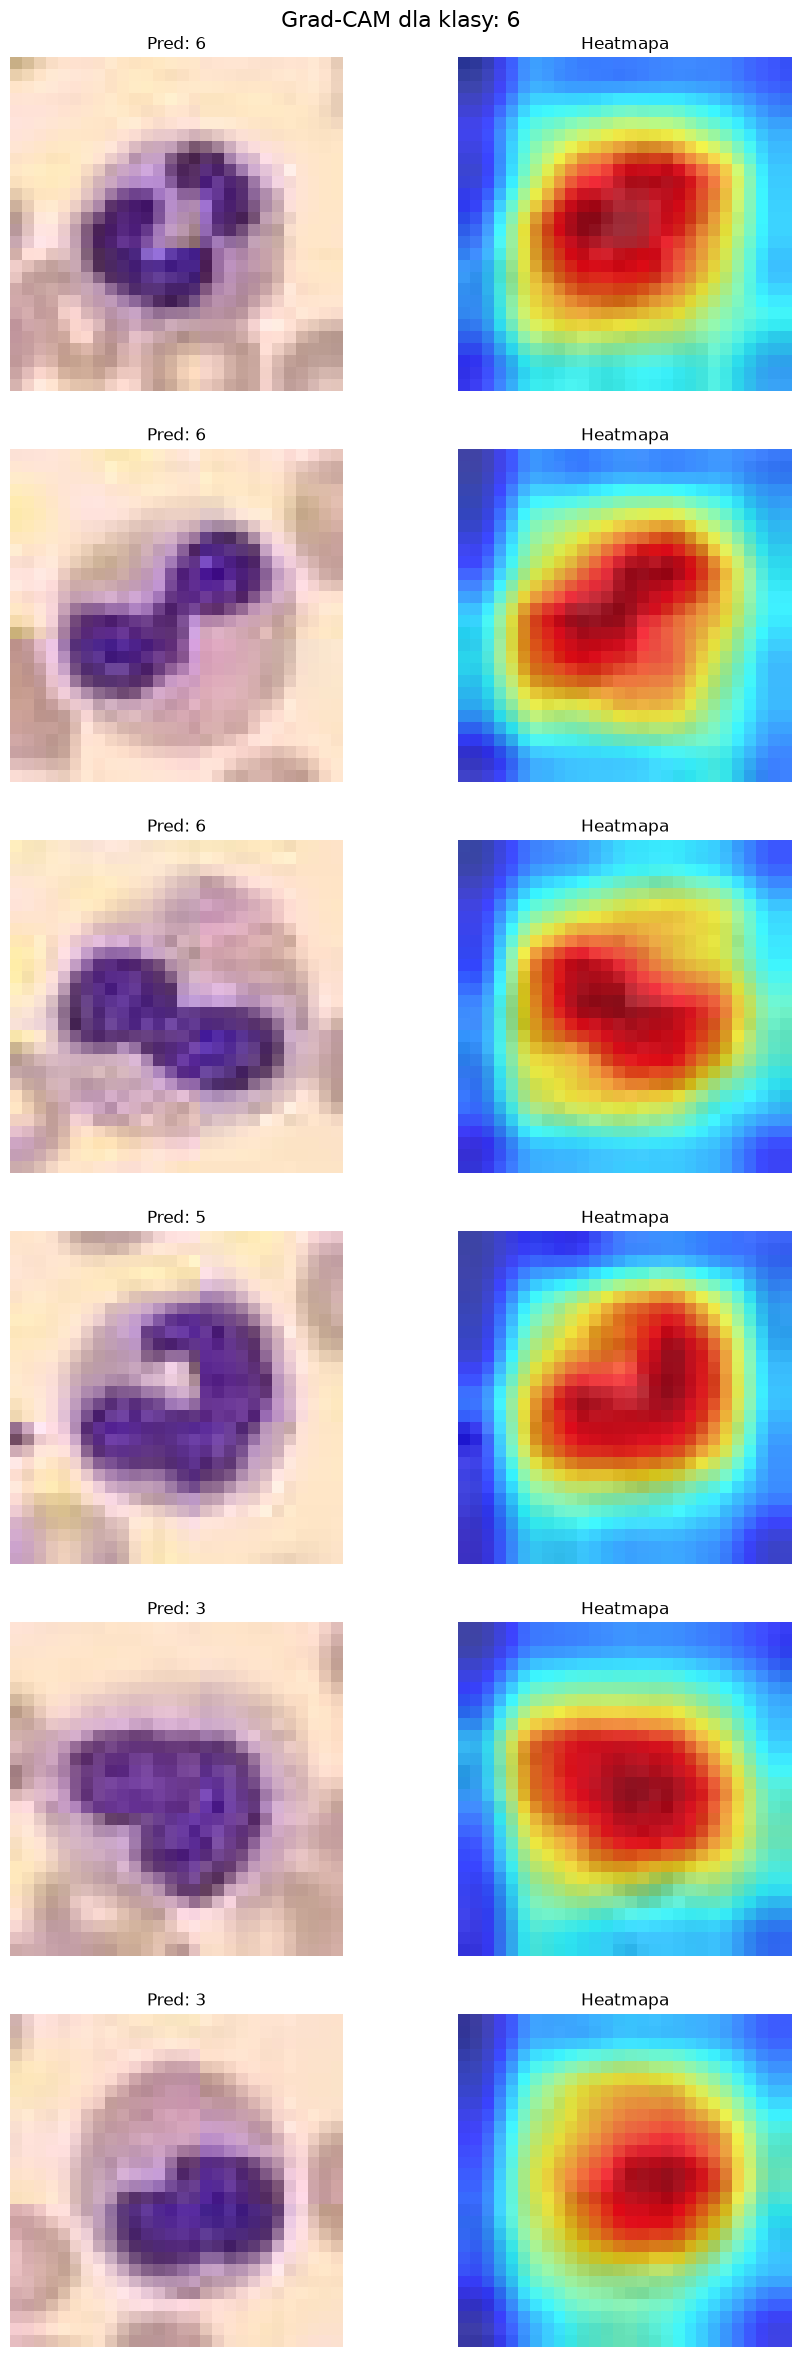

In [255]:
target_class = 6

class_indices = np.where(y_test.flatten() == target_class)[0]
correct_idx = [i for i in class_indices if y_pred.flatten()[i] == target_class][:3]
wrong_idx = [i for i in class_indices if y_pred.flatten()[i] != target_class][:3]

fig, axes = plt.subplots(6, 2, figsize=(10, 24))
fig.suptitle(f"Grad-CAM dla klasy: {target_class}", fontsize=16)



def draw_sample(row_idx, img_idx):
    ax_img = axes[row_idx, 0]
    ax_heat = axes[row_idx, 1]
    
    img = X_test[img_idx]
    pred_label = y_pred.flatten()[img_idx]
    
    img_tensor = torch.tensor(img).float().div(255.0).unsqueeze(0).permute(0,3,1,2).to(device)
    heatmap, _ = compute_heatmap(model, img_tensor)
    
    heatmap = upsampleHeatmap(heatmap, img_tensor)
    
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) 
    
    ax_img.imshow(img)
    ax_img.set_title(f"\nPred: {pred_label}")
    
    ax_heat.imshow(heatmap_rgb)
    ax_heat.set_title("Heatmapa")

    ax_heat.axis('off')
    ax_img.axis('off')

for i, idx in enumerate(correct_idx):
    draw_sample(row_idx=i, img_idx=idx)

for i, idx in enumerate(wrong_idx):
    draw_sample(row_idx=3 + i, img_idx=idx)

plt.tight_layout()
plt.show()

170
3421
torch.Size([1, 92, 7, 7])
torch.Size([1, 92, 7, 7])
torch.Size([1, 92, 7, 7])
torch.Size([1, 92, 7, 7])
torch.Size([1, 92, 7, 7])
torch.Size([1, 92, 7, 7])


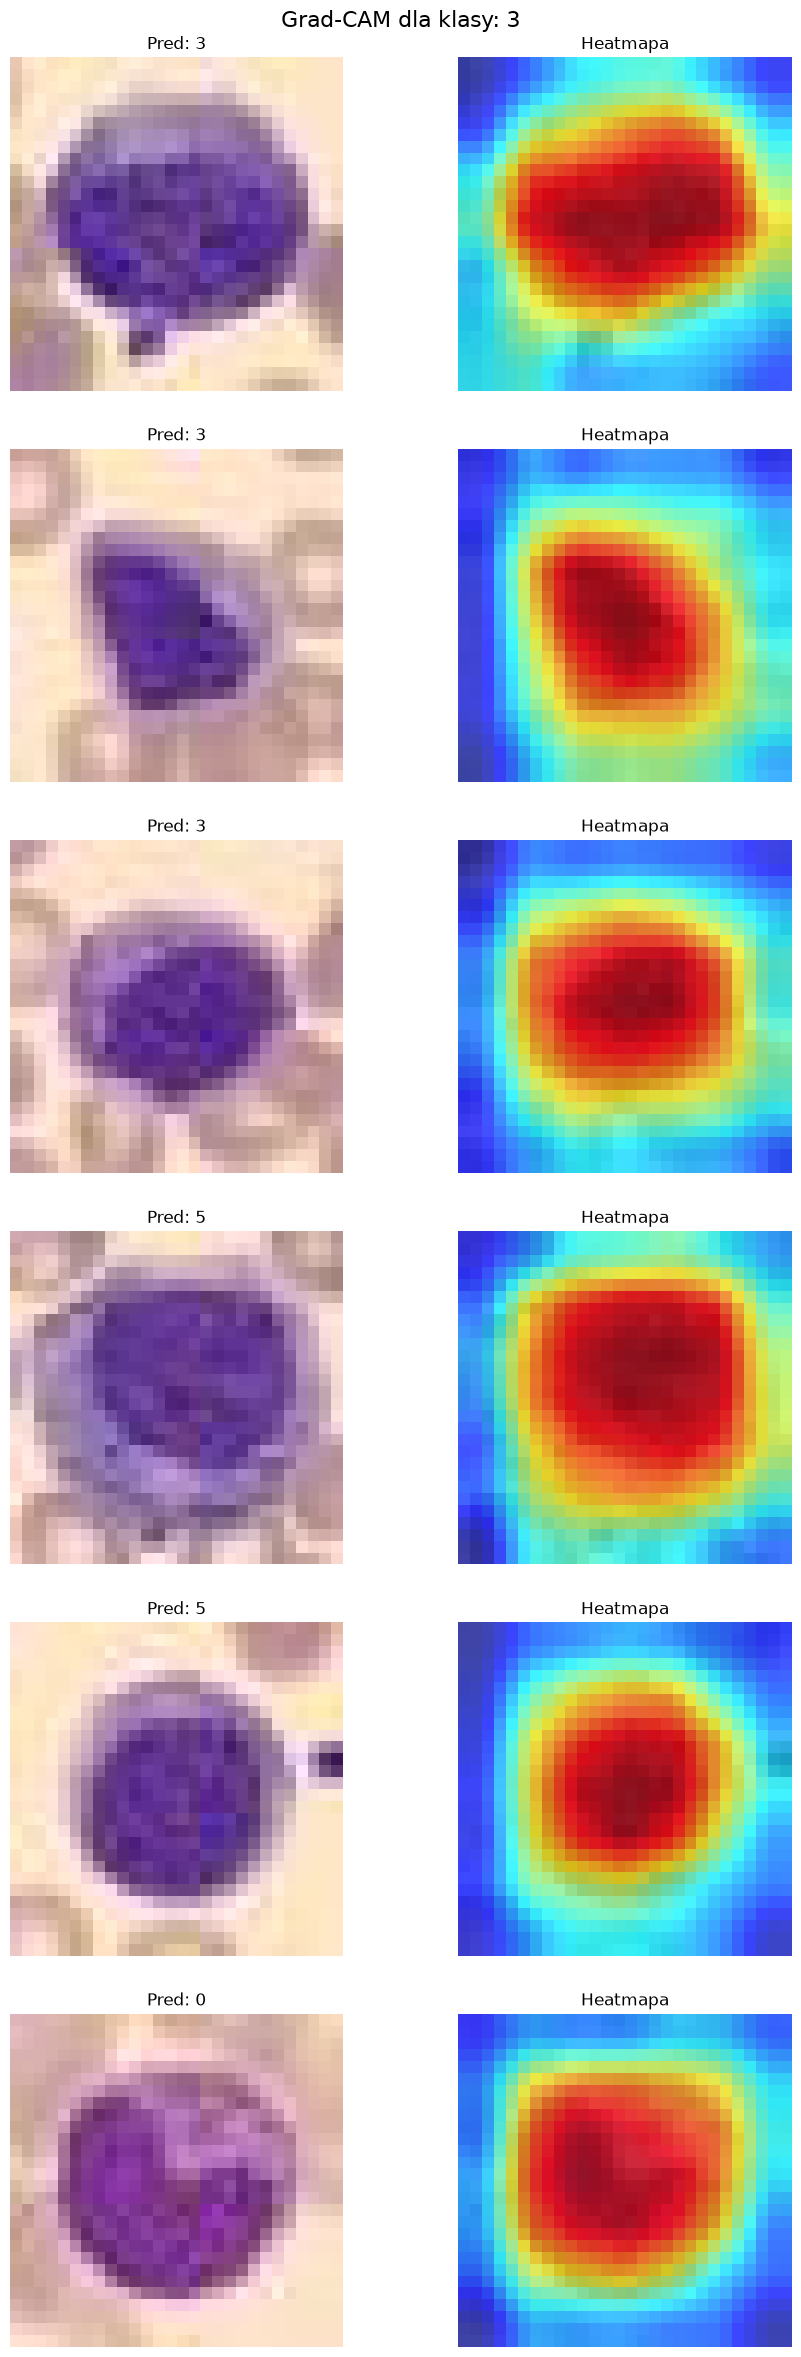

In [254]:
target_class = 3
wrong_preds = np.where(y_pred.numpy().flatten() != y_test.flatten())[0]
print(wrong_preds.shape[0])
print(y_pred.shape[0])

class_indices = np.where(y_test.flatten() == target_class)[0]
correct_idx = [i for i in class_indices if y_pred.flatten()[i] == target_class][:3]
wrong_idx = [i for i in class_indices if y_pred.flatten()[i] != target_class][:3]

fig, axes = plt.subplots(6, 2, figsize=(10, 24))
fig.suptitle(f"Grad-CAM dla klasy: {target_class}", fontsize=16)



for i, idx in enumerate(correct_idx):
    draw_sample(row_idx=i, img_idx=idx)

for i, idx in enumerate(wrong_idx):
    draw_sample(row_idx=3 + i, img_idx=idx)

plt.tight_layout()
plt.show()

## Oddanie zadania

Zapisz kod, wyniki, wykresy i uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i zadbaj o odtwarzalność rozwiązania. Umieść rozwiązania w swoim repozytorium.

https://medium.com/thedeephub/batch-normalization-for-training-neural-networks-328112bda3ae
https://medium.com/ai-enthusiast/understanding-relu-the-activation-function-driving-deep-learning-success-1cbe58eb555a
https://medium.com/data-science/conv2d-to-finally-understand-what-happens-in-the-forward-pass-1bbaafb0b148
https://medium.com/data-science/machine-learning-optimization-with-optuna-57593d700e52
https://medium.com/thedeephub/convolutional-neural-networks-a-comprehensive-guide-5cc0b5eae175
Grad-CAM
https://arxiv.org/abs/1610.02391
Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization